# 05 – Tree canopy object detection (Sentinel-2, 10 m)

**Important scope note.** A beech crown is roughly one Sentinel-2 pixel wide, so *individual* crowns cannot be resolved at 10 m. This notebook therefore detects **canopy units** from a pre-drought composite and aggregates all Sentinel-2 layers per unit. The sensitivity test in section 2 shows what a unit really is: even with the finest setting the median unit covers about 0.15 ha (some 15 pixels), a small patch of neighbouring trees. The first draft of this notebook assumed units of 1–4 pixels; the measured sizes do not support that, and the text now reports the measured values. The unit table is the interface to the training notebook (06). The same code path will later accept a high-resolution product (NIR orthophoto, canopy height model) without changes to the downstream notebook.

## Method (re-used from the literature)
| Step | Method | Source |
|---|---|---|
| Treetop candidates | Local-maximum filtering of a smoothed NIR image | Wulder et al. (2000); Popescu & Wynne (2004) |
| Crown/unit delineation | Marker-controlled watershed on the inverted image | Meyer & Beucher (1990); crown-following idea in Gougeon (1995) |
| Smoothing before peak search | Gaussian filter (NaN-aware) – the main tuning parameter, scale-matched to crown size | Popescu & Wynne (2004) |
| *Optional later*, high-res RGB | DeepForest (RetinaNet) | Weinstein et al. (2019, 2020) |
| *Reference for the target use case* | STDL HETRES delineates single trees from a segmented LiDAR point cloud | swisstopo (2025) |

Detection runs on the **pre-drought** composite (2017, peak window) so that dying crowns are still bright in NIR and units stay stable across years.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries
import rioxarray  # noqa: F401
import sds_utils as su
warnings.filterwarnings("ignore", category=FutureWarning)

YEARS = [2017, 2018, 2019, 2020, 2022, 2024, 2025, 2026]
REF_YEAR, REF_WIN, REF_VAR = 2017, "peak", "B08"     # detection image: NIR, pre-drought
SIGMA, MIN_DIST, MIN_PIX = 0.5, 1, 2                 # finest setting of the sensitivity test below
AOI_SHOW = "ajoie_ju"
VARS = ["NDVI", "NDRE", "NDMI", "NBR", "CIre"]

def load_ref(aoi):
    ds = su.open_nc(su.composite_path(aoi, REF_YEAR, REF_WIN)).load().rio.write_crs(su.CRS_UTM)
    anc = su.open_nc(su.PROC / f"{aoi}_ancillary.nc").load()
    return ds, anc

## 1 · Detection on one AOI

32435 units | forest 66.9 km2 | median unit area 1600 m2 | units per ha 4.85


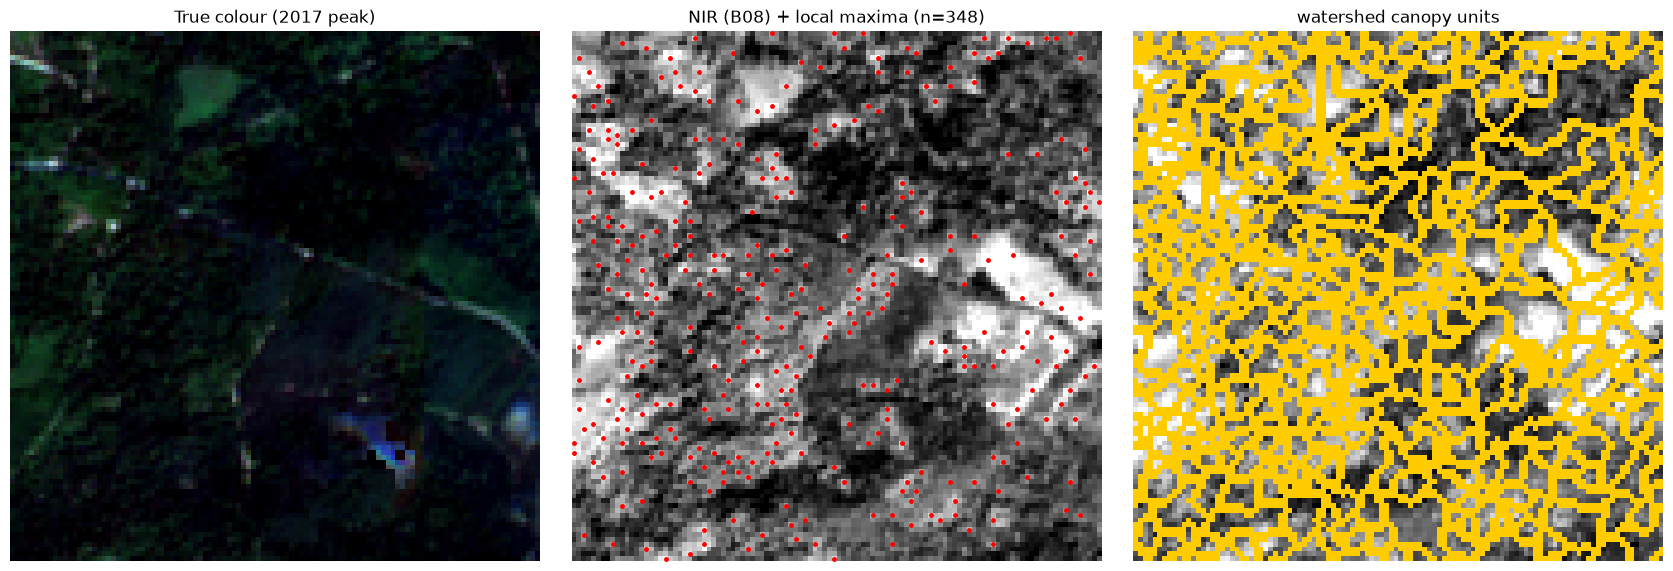

In [2]:
ds, anc = load_ref(AOI_SHOW)
img, forest = ds[REF_VAR].values, anc["forest"].values == 1
peaks, labels = su.detect_canopy_units(img, forest, sigma=SIGMA, min_distance=MIN_DIST)
area_m2 = np.bincount(labels.ravel())[1:] * 100.0
print(f"{len(peaks)} units | forest {forest.sum()*100/1e6:.1f} km2 | "
      f"median unit area {np.median(area_m2):.0f} m2 | units per ha {len(peaks)/(forest.sum()*100/1e4):.2f}")

# crop with the highest forest fraction for a readable overlay
S = 110
best = max(((r, c_) for r in range(0, img.shape[0] - S, 55) for c_ in range(0, img.shape[1] - S, 55)),
           key=lambda rc: forest[rc[0]:rc[0]+S, rc[1]:rc[1]+S].mean())
r0, c0 = best; sl = (slice(r0, r0 + S), slice(c0, c0 + S))
base = su.stretch(img[sl])
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))
ax[0].imshow(su.rgb(ds)[sl]); ax[0].set_title("True colour (2017 peak)")
ax[1].imshow(base, cmap="gray"); pk = peaks[(peaks[:, 0] >= r0) & (peaks[:, 0] < r0 + S) & (peaks[:, 1] >= c0) & (peaks[:, 1] < c0 + S)]
ax[1].plot(pk[:, 1] - c0, pk[:, 0] - r0, "r.", ms=5); ax[1].set_title(f"NIR (B08) + local maxima (n={len(pk)})")
ax[2].imshow(mark_boundaries(np.dstack([base] * 3), labels[sl], color=(1, 0.8, 0), mode="inner")); ax[2].set_title("watershed canopy units")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(su.FIGS / "05_detection_example.png", dpi=150); plt.show()

## 2 · Parameter sensitivity
The smoothing width (`sigma`) and the minimum peak distance (`min_distance`) control the unit size. No reference crowns are available, so the parameters cannot be tuned against truth. The table shows the median unit area for each setting. Local NIR maxima at 10 m are several pixels apart whatever the setting, so the smallest achievable units are well above crown size. The finest setting (`sigma = 0.5`, `min_distance = 1`) is used, to keep units as homogeneous as possible.

In [3]:
rows = []
for sg in (0.5, 1.0, 1.5, 2.0):
    for md_ in (1, 2, 3):
        pk, lb = su.detect_canopy_units(img, forest, sigma=sg, min_distance=md_)
        a = np.bincount(lb.ravel())[1:] * 100.0
        rows.append(dict(sigma=sg, min_distance=md_, n_units=len(pk), units_per_ha=len(pk) / (forest.sum() * 100 / 1e4),
                         median_area_m2=np.median(a), p90_area_m2=np.percentile(a, 90)))
sens = pd.DataFrame(rows)
sens.to_csv(su.TABLES / "05_sensitivity.csv", index=False)
sens.pivot(index="sigma", columns="min_distance", values="median_area_m2").round(0)

min_distance,1,2,3
sigma,,,
0.5,1600.0,3000.0,4900.0
1.0,3400.0,4500.0,6200.0
1.5,5300.0,6600.0,8200.0
2.0,7300.0,9000.0,10400.0


## 3 · Run on all AOIs, save units
Outputs per AOI: `*_canopy_units.gpkg` (polygons) and `features_*.csv.gz` (one row per unit). Units smaller than `MIN_PIX` pixels are discarded.

In [4]:
def detect_aoi(aoi):
    ds, anc = load_ref(aoi)
    forest = anc["forest"].values == 1
    peaks, labels = su.detect_canopy_units(ds[REF_VAR].values, forest, sigma=SIGMA, min_distance=MIN_DIST)
    n = np.bincount(labels.ravel()); small = np.where(n < MIN_PIX)[0]
    labels[np.isin(labels, small[small > 0])] = 0
    return ds, anc, labels

def build_features(aoi, ds_ref, anc, labels):
    base = {}
    for w in su.WINDOWS:
        d = su.open_nc(su.composite_path(aoi, REF_YEAR, w)).load()
        base[w] = {v: d[v].values for v in VARS}
    parts = []
    for w in su.WINDOWS:
        for y in YEARS:
            p = su.composite_path(aoi, y, w)
            if not p.exists(): continue
            d = su.open_nc(p).load()
            layers = {}
            for v in VARS:
                a = d[v].values
                layers[f"{v}_{w}_{y}"] = a
                if y != REF_YEAR: layers[f"d{v}_{w}_{y}"] = a - base[w][v]
            parts.append(su.zonal_stats(labels, layers, stats=("mean",)).drop(columns="n_pix"))
            parts.append(su.zonal_stats(labels, {f"NDVI_{w}_{y}": d["NDVI"].values}, stats=("std",)).drop(columns="n_pix"))
    terr = {"elev": anc["elevation"].values, "slope": anc["slope"].values,
            "northness": np.cos(np.radians(anc["aspect"].values)), "eastness": np.sin(np.radians(anc["aspect"].values))}
    parts.append(su.zonal_stats(labels, terr, stats=("mean",)))          # includes n_pix
    X = pd.concat(parts, axis=1)
    # unit centroid (UTM) for spatial blocking
    lab = labels.ravel(); keep = lab > 0
    rr, cc = np.indices(labels.shape)
    cen = pd.DataFrame({"r": rr.ravel()[keep], "c": cc.ravel()[keep]}).groupby(lab[keep]).mean()
    xs, ys = ds_ref.x.values, ds_ref.y.values
    X["x"] = xs[0] + cen["c"] * (xs[1] - xs[0]); X["y"] = ys[0] + cen["r"] * (ys[1] - ys[0])
    return X

summary = []
for aoi in su.AOIS:
    ds_r, anc_r, labels = detect_aoi(aoi)
    gdf = su.labels_to_gdf(labels, ds_r.rio.transform())
    gdf.to_file(su.PROC / f"{aoi}_canopy_units.gpkg", driver="GPKG")
    feats = build_features(aoi, ds_r, anc_r, labels)
    feats.to_csv(su.PROC / f"features_{aoi}.csv.gz")
    a = np.bincount(labels.ravel())[1:]; a = a[a > 0] * 100.0
    f_km2 = (anc_r["forest"].values == 1).sum() * 100 / 1e6
    summary.append(dict(aoi=aoi, n_units=len(gdf), units_per_km2=len(gdf) / f_km2,
                        median_area_m2=np.median(a), forest_covered=(labels > 0).sum() / (anc_r["forest"].values == 1).sum(),
                        n_features=feats.shape[1]))
pd.DataFrame(summary).set_index("aoi").round(2)

,n_units,units_per_km2,median_area_m2,forest_covered,n_features
aoi,,,,,
ajoie_ju,32123,480.05,1700.0,1.0,173
fricktal_ag,29345,437.02,1800.0,1.0,173
valais_rhone,38921,461.36,1600.0,1.0,173


## 4 · Quality checks

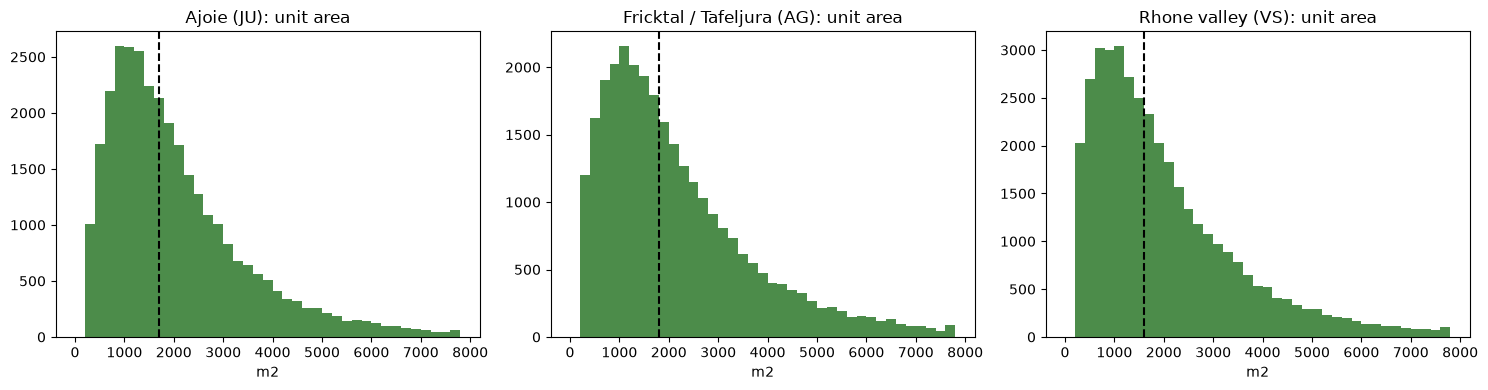

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, aoi in enumerate(su.AOIS):
    g = su.PROC / f"{aoi}_canopy_units.gpkg"
    import geopandas as gpd
    a = gpd.read_file(g).area
    ax[j].hist(a, bins=np.arange(0, 8000, 200), color="#4c8c4a"); ax[j].set_title(f"{su.AOIS[aoi]['label']}: unit area")
    ax[j].set_xlabel("m2"); ax[j].axvline(a.median(), color="k", ls="--")
plt.tight_layout(); plt.savefig(su.FIGS / "05_unit_area_hist.png", dpi=150); plt.show()

**What to verify before trusting the units (not done yet – no reference data):**
1. Visual check against SWISSIMAGE / NIR orthophotos in QGIS for a few windows per AOI.
2. Compare unit centroids with LiDAR-derived tree tops (swissSURFACE3D / canopy height model) in a small test area; report detection rate and commission error.
3. Check that unit statistics are stable if a different pre-drought year is used for detection.

## 5 · Optional: high-resolution detection with DeepForest (next phase)
Not run here (Sentinel-2 only for now). Once RGB/NIR orthophotos are available, a pretrained RGB detector can produce true crown boxes that replace the Sentinel-2 units; notebook 06 only needs a polygon layer with `unit_id`. The DeepForest API changed between versions – check its documentation before use.

In [6]:
RUN_DEEPFOREST = False
if RUN_DEEPFOREST:
    from deepforest import main            # pip install deepforest  (API depends on version)
    model = main.deepforest(); model.use_release()
    boxes = model.predict_tile("../data/highres/ortho_rgb.tif", patch_size=400, patch_overlap=0.25)
    print(boxes.head())

## References
- Wulder, M., Niemann, K.O., Goodenough, D.G. (2000): Local maximum filtering for the extraction of tree locations and basal area from high spatial resolution imagery. *Remote Sensing of Environment* 73(1), 103–114.
- Popescu, S.C., Wynne, R.H. (2004): Seeing the trees in the forest: using lidar and multispectral data fusion with local filtering and variable window size for estimating tree height. *Photogrammetric Engineering & Remote Sensing* 70(5), 589–604.
- Meyer, F., Beucher, S. (1990): Morphological segmentation. *Journal of Visual Communication and Image Representation* 1(1), 21–46.
- Gougeon, F.A. (1995): A crown-following approach to the automatic delineation of individual tree crowns in high spatial resolution aerial images. *Canadian Journal of Remote Sensing* 21(3), 274–284.
- Weinstein, B.G. et al. (2019): Individual tree-crown detection in RGB imagery using semi-supervised deep learning neural networks. *Remote Sensing* 11(11), 1309.
- Weinstein, B.G. et al. (2020): DeepForest: a Python package for RGB deep learning tree crown delineation. *Methods in Ecology and Evolution* 11(12), 1743–1751.
- swisstopo (2025): CLASSIFY – Gesundheitsgrad von Buchen (STDL PROJ-HETRES). https://www.swisstopo.admin.ch/de/classify-gesundheitsgrad-von-buchen
- scikit-image `peak_local_max`, `watershed`: van der Walt et al. (2014), *PeerJ* 2:e453.